In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Find the dataset saved in Notebook 3
matches = list(Path.cwd().rglob("turkish_crowdfunding_cluster_ready.csv"))

if not matches:
    raise FileNotFoundError(
        "Could not find turkish_crowdfunding_cluster_ready.csv. "
        "Make sure Notebook 3 was run and saved."
    )

file_path = matches[0]
X_cluster = pd.read_csv(file_path)

print("Loaded file:", file_path)
print("Dataset shape:", X_cluster.shape)

X_cluster.head()

Loaded file: C:\Users\kavya\Turkish Crowdfunding Startups\processed_data\turkish_crowdfunding_cluster_ready.csv
Dataset shape: (1628, 130)


,0,1,2,3,4,5,6,7,8,9,...,120,121,122,123,124,125,126,127,128,129
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.141320,1.447608,-0.106091,2.250624,1.182774,1.605842,-0.116484,-0.641784,-0.177344,0.135005
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.141320,-0.212921,-0.106091,2.250624,2.803157,1.605842,0.158918,-0.641784,-0.623855,0.287282
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.553754,0.202211,-0.024196,0.009087,0.102518,0.789380,-0.104358,1.225641,0.195859,0.241599
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.141320,-0.212921,-0.106091,0.457395,-0.437610,0.789380,0.040947,1.692498,-0.223994,0.058866
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.141320,-0.212921,-0.106091,0.905702,2.263029,-0.027082,-0.123164,0.758785,0.722342,-0.017273


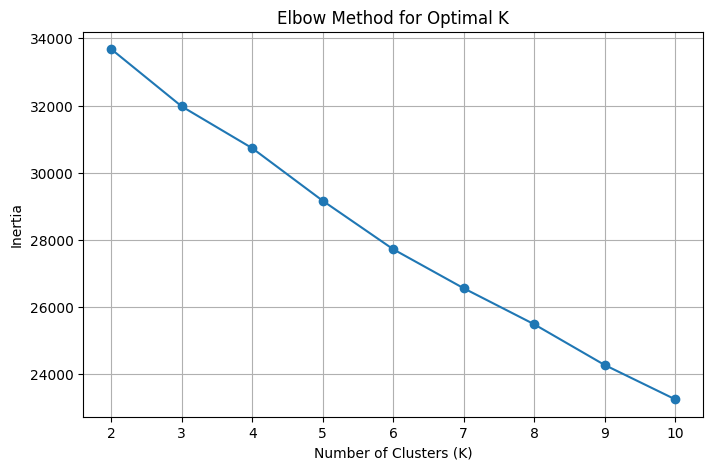

In [4]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"  # Use 4 logical cores
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_cluster)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [5]:
# Set K based on the Elbow plot
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

# Add cluster labels to the dataset
clustered_df = X_cluster.copy()
clustered_df["Cluster"] = cluster_labels

print("K-Means clustering completed.")
print("Number of clusters:", optimal_k)
print("\nCluster counts:")
print(clustered_df["Cluster"].value_counts().sort_index())

clustered_df.head()

K-Means clustering completed.
Number of clusters: 3

Cluster counts:
Cluster
0      1
1    820
2    807
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,121,122,123,124,125,126,127,128,129,Cluster
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.447608,-0.106091,2.250624,1.182774,1.605842,-0.116484,-0.641784,-0.177344,0.135005,1
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,2.250624,2.803157,1.605842,0.158918,-0.641784,-0.623855,0.287282,1
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.202211,-0.024196,0.009087,0.102518,0.789380,-0.104358,1.225641,0.195859,0.241599,1
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,0.457395,-0.437610,0.789380,0.040947,1.692498,-0.223994,0.058866,1
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,0.905702,2.263029,-0.027082,-0.123164,0.758785,0.722342,-0.017273,1


In [6]:
# Set K based on the Elbow plot
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster)

# Add cluster labels to the dataset
clustered_df = X_cluster.copy()
clustered_df["Cluster"] = cluster_labels

print("K-Means clustering completed.")
print("Number of clusters:", optimal_k)
print("\nCluster counts:")
print(clustered_df["Cluster"].value_counts().sort_index())

clustered_df.head()

K-Means clustering completed.
Number of clusters: 3

Cluster counts:
Cluster
0      1
1    820
2    807
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9,...,121,122,123,124,125,126,127,128,129,Cluster
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,1.447608,-0.106091,2.250624,1.182774,1.605842,-0.116484,-0.641784,-0.177344,0.135005,1
1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,2.250624,2.803157,1.605842,0.158918,-0.641784,-0.623855,0.287282,1
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.202211,-0.024196,0.009087,0.102518,0.789380,-0.104358,1.225641,0.195859,0.241599,1
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,0.457395,-0.437610,0.789380,0.040947,1.692498,-0.223994,0.058866,1
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,...,-0.212921,-0.106091,0.905702,2.263029,-0.027082,-0.123164,0.758785,0.722342,-0.017273,1


In [7]:
score = silhouette_score(X_cluster, cluster_labels)

print("Silhouette Score:", round(score, 4))

if score >= 0.7:
    print("The clusters are well separated.")
elif score >= 0.5:
    print("The clustering structure is reasonable.")
elif score >= 0.25:
    print("The clusters show some structure, but overlap may exist.")
else:
    print("The clusters may be weakly separated.")

Silhouette Score: 0.1286
The clusters may be weakly separated.


In [8]:
score = silhouette_score(X_cluster, cluster_labels)

print("Silhouette Score:", round(score, 4))

if score >= 0.7:
    print("The clusters are well separated.")
elif score >= 0.5:
    print("The clustering structure is reasonable.")
elif score >= 0.25:
    print("The clusters show some structure, but overlap may exist.")
else:
    print("The clusters may be weakly separated.")

Silhouette Score: 0.1286
The clusters may be weakly separated.


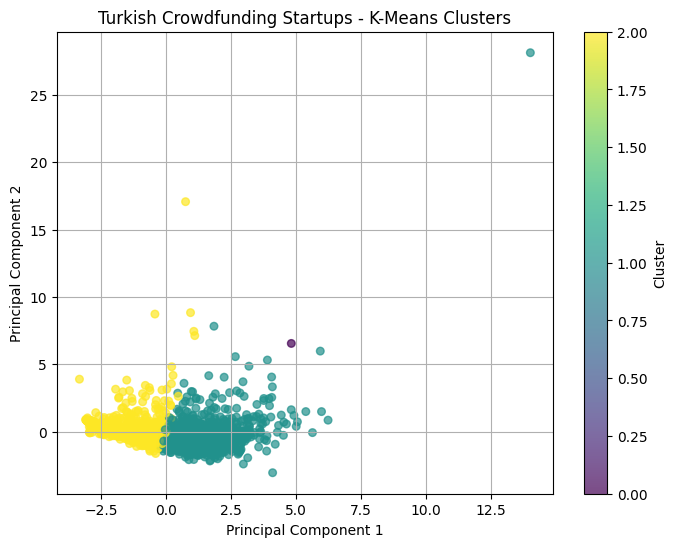

Explained variance by 2 components: 0.2225


In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    s=30,
    alpha=0.7
)

plt.title("Turkish Crowdfunding Startups - K-Means Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

print("Explained variance by 2 components:",
      round(pca.explained_variance_ratio_.sum(), 4))

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

output_file = output_dir / "turkish_crowdfunding_clustered_results.csv"
clustered_df.to_csv(output_file, index=False)

print("Clustered results saved to:", output_file)
print("Final result shape:", clustered_df.shape)